# BanglaTaka: classifying Bangladeshi banknotes with a CNN built from scratch

| | |
|---|---|
| **Dataset** | BanglaTaka: images of Bangladeshi banknotes, 9 denominations (2, 5, 10, 20, 50, 100, 200, 500, 1000 Taka) |
| **Source** | Mendeley Data, DOI 10.17632/3cv2sypkkh.1; described in Data in Brief, DOI 10.1016/j.dib.2025.111853. Licence: CC BY 4.0 |
| **Student** | [Tahmid Jawad Shafi, 22-49127-3] |

**Goal:** build a basic CNN from scratch in PyTorch, experiment with the number of convolution layers, the number of channels and the hidden layer, and analyse the results.

We follow the same flow as the class notebooks:

1. Get the data and look at it.
2. Build a CNN and train it. **Round 1:** no augmentation.
3. Read the curves, spot overfitting. **Round 2:** augmentation and dropout.
4. Our own experiments (layers, channels, kernel size, hidden layer).
5. Final model on the test set: confusion matrix, classification report, misclassified images, filters and feature maps.

> Run the cells top to bottom (`Shift + Enter`).

## 1. Setup

In [7]:
# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Data + image transforms
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# Plotting + utilities
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os, shutil, math, json, time, random
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report, f1_score, accuracy_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cpu":
    print("No GPU found. On Kaggle: Settings > Accelerator > GPU. It still runs on CPU, only slower.")

Using device: cuda


In [8]:
# ------------------------- Settings you may edit -------------------------
DATA_DIR = None          # None = auto-detect under /kaggle/input. Or set a folder (or a list of folders)
SEARCH_ROOTS = ["/kaggle/input", "/content", "."]
KAGGLE_DATASET = None    # optional "username/dataset-slug" to download with kagglehub (not needed if attached)

SEED = 42
IMG_SIZE = 128           # every image is resized to IMG_SIZE x IMG_SIZE
BATCH_SIZE = 32
LR = 1e-3
EPOCHS = 20
VAL_FRAC, TEST_FRAC = 0.15, 0.15
HFLIP = False            # banknotes: mirroring flips the printed text and digits, so no horizontal flip

MIN_IMAGES, MAX_GB = 2000, 2.5   # assignment limits
# --------------------------------------------------------------------------

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "outputs"
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

def savefig(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

set_seed(SEED)

## 2. Get the data

The dataset must be on Kaggle first: **Kaggle > Datasets > New Dataset**, upload the dataset folder (or its zip, Kaggle unzips it), then in the notebook use **Add Input** to attach it. It then appears under `/kaggle/input/`.

The cell below finds the folder whose sub-folders are the classes (like the class notebook's `find_split_dir`). If you did not attach the dataset, set `KAGGLE_DATASET` in the settings cell and it is downloaded with `kagglehub`.

> **Use the original images only.** If the dataset also contains an `Augmented` folder, point `DATA_DIR` at the original folder. Rotated or flipped copies of one photo in both train and test would inflate the test accuracy (data leakage).

In [9]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SPLIT_NAMES = {"train", "training", "val", "valid", "validation", "test", "testing"}

def is_img(name):
    return os.path.splitext(name)[1].lower() in IMG_EXT

def find_class_roots(root, min_classes=2, min_imgs=3):
    """Folders whose sub-folders look like classes (each holds some images directly)."""
    found = []
    for cur, dirs, _ in os.walk(root):
        good = 0
        for d in dirs:
            try:
                n = sum(is_img(f) for f in os.listdir(os.path.join(cur, d)))
            except OSError:
                n = 0
            good += n >= min_imgs
        if good >= min_classes:
            found.append(cur)
    return found

if KAGGLE_DATASET:
    import kagglehub
    SEARCH_ROOTS = [kagglehub.dataset_download(KAGGLE_DATASET)]

if DATA_DIR is not None:
    SRC_DIRS = [DATA_DIR] if isinstance(DATA_DIR, str) else list(DATA_DIR)
else:
    candidates = []
    for r in SEARCH_ROOTS:
        if os.path.isdir(r):
            candidates += find_class_roots(r)
    candidates = list(dict.fromkeys(candidates))
    print("Candidate dataset folders:")
    for c in candidates:
        print("  ", c)
    if len(candidates) == 1:
        SRC_DIRS = candidates
    elif candidates and all(os.path.basename(c.rstrip("/")).lower() in SPLIT_NAMES for c in candidates):
        SRC_DIRS = candidates          # dataset ships as train/val/test folders: pool them and re-split ourselves
        print("Dataset is pre-split (train/val/test): the folders are pooled and re-split below.")
    else:
        raise ValueError("Zero or several candidate folders. Choose the ORIGINAL images folder and set DATA_DIR in the settings cell.")
print("Source folder(s):", SRC_DIRS)

Candidate dataset folders:
   /kaggle/input/datasets/tahmidxshafi/banglataka-bangladeshi-banknote-images/Bangladeshi_Paper_Currency_Raw
Source folder(s): ['/kaggle/input/datasets/tahmidxshafi/banglataka-bangladeshi-banknote-images/Bangladeshi_Paper_Currency_Raw']


Classes      : 9
Total images : 5,073
Size on disk : 1.71 GB
Assignment check -> images >= 2000: PASS | size <= 2.5 GB: PASS


,images,share_%
10,419,8.3
100,565,11.1
1000,422,8.3
2,445,8.8
20,480,9.5
200,423,8.3
5,660,13.0
50,416,8.2
500,1243,24.5


Imbalance ratio (largest / smallest class): 3.0


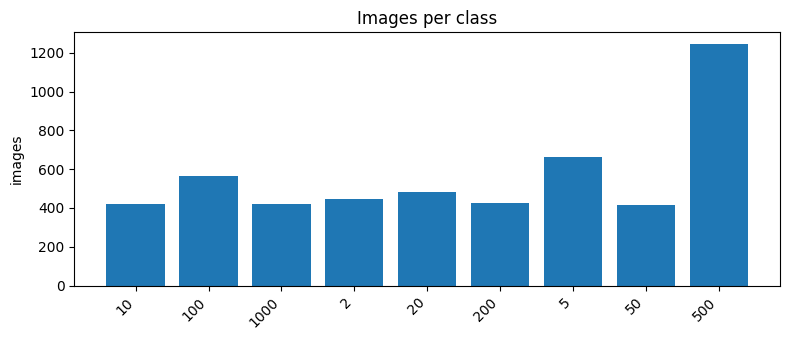

Original image size (200 sampled): width 520-3106 px, height 476-3384 px


In [10]:
# List every image: (path, class name, source folder)
items = []
for d in SRC_DIRS:
    for cls in sorted(os.listdir(d)):
        cdir = os.path.join(d, cls)
        if os.path.isdir(cdir):
            for f in sorted(os.listdir(cdir)):
                if is_img(f):
                    items.append((os.path.join(cdir, f), cls, os.path.basename(d.rstrip("/"))))

class_list = sorted({c for _, c, _ in items})
counts = pd.Series([c for _, c, _ in items]).value_counts().reindex(class_list)
total_bytes = sum(os.path.getsize(p) for p, _, _ in items)

print(f"Classes      : {len(class_list)}")
print(f"Total images : {len(items):,}")
print(f"Size on disk : {total_bytes / 1024**3:.2f} GB")
print(f"Assignment check -> images >= {MIN_IMAGES}: {'PASS' if len(items) >= MIN_IMAGES else 'CHECK'}"
      f" | size <= {MAX_GB} GB: {'PASS' if total_bytes / 1024**3 <= MAX_GB else 'CHECK'}")
display(counts.rename("images").to_frame().assign(**{"share_%": (100 * counts / counts.sum()).round(1)}))
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.1f}")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(counts.index, counts.values)
ax.set_title("Images per class"); ax.set_ylabel("images")
plt.xticks(rotation=45, ha="right"); plt.tight_layout()
savefig("class_distribution.png"); plt.show()

# Original image sizes (200 sampled)
rng = np.random.default_rng(SEED)
sizes = []
for i in rng.choice(len(items), size=min(200, len(items)), replace=False):
    try:
        with Image.open(items[i][0]) as im:
            sizes.append(im.size)
    except Exception:
        pass
w, h = zip(*sizes)
print(f"Original image size (200 sampled): width {min(w)}-{max(w)} px, height {min(h)}-{max(h)} px")

### Resize once, then use `ImageFolder`

Decoding large photos in every epoch is slow. So we first write a copy of the dataset where every image is already `IMG_SIZE x IMG_SIZE` (one folder per class), and then use `ImageFolder` exactly as in the class notebook. Unreadable files are skipped and reported. The originals are not changed.

In [11]:
RESIZED_DIR = os.path.join(OUT_DIR, f"resized_{IMG_SIZE}")
shutil.rmtree(RESIZED_DIR, ignore_errors=True)
for c in class_list:
    os.makedirs(os.path.join(RESIZED_DIR, c))

def resize_one(job):
    i, (path, cls, src) = job
    try:
        with Image.open(path) as im:
            im = im.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        im.save(os.path.join(RESIZED_DIR, cls, f"{src}_{i:05d}.jpg"), quality=95)
        return None
    except Exception:
        return path

with ThreadPoolExecutor(max_workers=8) as ex:
    failed = [p for p in tqdm(ex.map(resize_one, enumerate(items)), total=len(items), desc="Resizing") if p]
if failed:
    print(f"Skipped {len(failed)} unreadable file(s), e.g. {failed[:3]}")

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),     # images are already this size
    transforms.ToTensor(),                       # PIL -> tensor in [0, 1], shape [C, H, W]
])
full_ds = datasets.ImageFolder(RESIZED_DIR, transform=basic_transform)
class_names = full_ds.classes
num_classes = len(class_names)
targets = np.array(full_ds.targets)
print("Classes:", class_names)
print("Images :", len(full_ds))

Resizing:   0%|          | 0/5073 [00:00<?, ?it/s]

Classes: ['10', '100', '1000', '2', '20', '200', '5', '50', '500']
Images : 5073


### Train / validation / test split

| Split | Used for |
|---|---|
| **Train** (70%) | the network learns from these images |
| **Validation** (15%) | checking progress and **comparing experiments** |
| **Test** (15%) | used **once**, at the end, for the final honest result |

The split is **stratified** (every class keeps its share in all three) and is made **before** any augmentation. Augmentation is applied to the training images only.

In [12]:
idx_all = np.arange(len(targets))
idx_train, idx_tmp = train_test_split(idx_all, test_size=VAL_FRAC + TEST_FRAC, stratify=targets, random_state=SEED)
idx_val, idx_test = train_test_split(idx_tmp, test_size=TEST_FRAC / (VAL_FRAC + TEST_FRAC),
                                     stratify=targets[idx_tmp], random_state=SEED)

split_df = pd.DataFrame({
    "class": class_names,
    "train": np.bincount(targets[idx_train], minlength=num_classes),
    "val": np.bincount(targets[idx_val], minlength=num_classes),
    "test": np.bincount(targets[idx_test], minlength=num_classes),
})
display(pd.concat([split_df, pd.DataFrame([{"class": "TOTAL", "train": len(idx_train), "val": len(idx_val), "test": len(idx_test)}])],
                  ignore_index=True))

# Transforms: basic (validation/test, and Round 1 training) and augmented (Round 2 training)
aug_ops = []
if HFLIP:
    aug_ops.append(transforms.RandomHorizontalFlip())
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    *aug_ops,
    transforms.RandomRotation(15),                                           # small rotations
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),    # lighting changes
    transforms.ToTensor(),
])

def make_loaders(augment=False):
    """ImageFolder + Subset(indices) + DataLoader. Only the training images are augmented."""
    train_full = datasets.ImageFolder(RESIZED_DIR, transform=train_transform if augment else basic_transform)
    eval_full = datasets.ImageFolder(RESIZED_DIR, transform=basic_transform)
    g = torch.Generator(); g.manual_seed(SEED)
    pin = device.type == "cuda"
    train_loader = DataLoader(Subset(train_full, idx_train), batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=2, pin_memory=pin)
    val_loader = DataLoader(Subset(eval_full, idx_val), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=pin)
    test_loader = DataLoader(Subset(eval_full, idx_test), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=pin)
    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders(augment=False)

,class,train,val,test
0,10,293,63,63
1,100,396,85,84
2,1000,295,64,63
3,2,312,66,67
4,20,336,72,72
5,200,296,63,64
6,5,462,99,99
7,50,291,62,63
8,500,870,187,186
9,TOTAL,3551,761,761


### Look at a few images

Always eyeball your data before training.

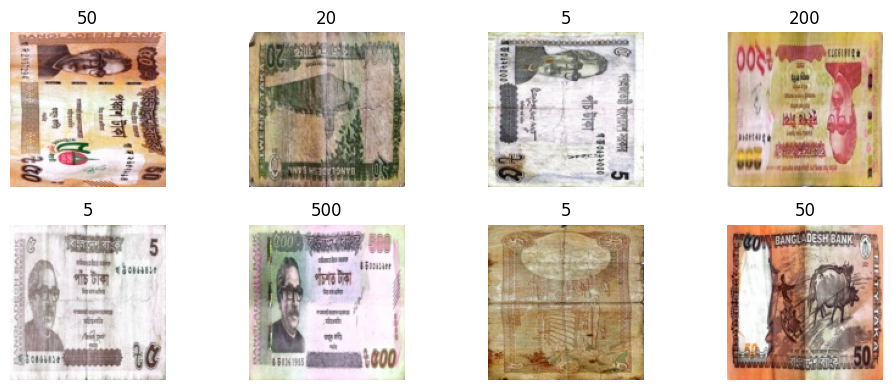

In [13]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(images[i].permute(1, 2, 0))       # tensor is [C, H, W]; matplotlib wants [H, W, C]
    plt.title(class_names[labels[i]])
    plt.axis("off")
plt.tight_layout()
savefig("sample_images.png"); plt.show()

## 3. Build the CNN

A CNN has two parts.

**A) Feature extractor (convolution + pooling).** A **filter** is a small grid of numbers (here `3 x 3`) that slides over the image and responds to one pattern (an edge, a corner, a colour patch). A **convolution layer** is a stack of filters; each filter makes one **feature map**. **ReLU** replaces negative numbers by 0. **MaxPool** halves the height and width and keeps the strongest signals.

**B) Classification head (fully connected layers).** The feature maps are flattened into one vector; a **hidden layer** and a final `Linear` layer turn it into one score per class.

For a `128 x 128` image and three conv layers (16, 32, 64 filters):

```
Image 3x128x128
  -> Conv(16) -> ReLU -> Pool  -> 16x64x64
  -> Conv(32) -> ReLU -> Pool  -> 32x32x32
  -> Conv(64) -> ReLU -> Pool  -> 64x16x16
  -> Flatten                   -> 16384 numbers
  -> Linear(128) -> ReLU -> Dropout
  -> Linear(9)                 -> one score per class
```

The class below takes the **channels** (one number per conv layer), the **kernel size**, the **hidden layer size** and the **dropout** as arguments, so our experiments only change these arguments.

In [14]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes, channels=(16, 32, 64), kernel_size=3, hidden=128, p_dropout=0.0):
        super().__init__()
        # --- Feature extractor: one Conv -> ReLU -> MaxPool block per entry of `channels` ---
        layers, in_ch = [], 3
        for out_ch in channels:
            layers += [nn.Conv2d(in_ch, out_ch, kernel_size, padding=kernel_size // 2),   # padding keeps H and W
                       nn.ReLU(),
                       nn.MaxPool2d(2)]                                                     # halves H and W
            in_ch = out_ch
        self.conv_layers = nn.Sequential(*layers)

        # --- Size after the conv layers: each pool halves the image (128 -> 64 -> 32 -> 16) ---
        side = IMG_SIZE // (2 ** len(channels))
        flat_features = channels[-1] * side * side          # last layer's channels * image size after the pools

        # --- Classification head ---
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_features, hidden),
            nn.ReLU(),
            nn.Dropout(p_dropout),                           # 0.0 = off
            nn.Linear(hidden, num_classes),
        )

    def forward(self, x):
        x = self.conv_layers(x)
        return self.fc_layers(x)                             # raw scores (logits)

def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

model = SimpleCNN(num_classes).to(device)
print(model)
print(f"\nTotal trainable parameters: {count_params(model):,}")

SimpleCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=16384, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.0, inplace=False)
    (4): Linear(in_features=128, out_features=9, bias=True)
  )
)

Total trainable parameters: 2,122,025


## 4. Train the model: Round 1 (no augmentation)

**The training loop in plain words:** show the model a batch of images; it guesses; `CrossEntropyLoss` measures how wrong it is; backpropagation computes how to change every weight; `Adam` applies the change. One pass over all training images is one **epoch**; after each epoch we check the loss and accuracy on the validation images.

We also keep the weights of the epoch with the **highest validation accuracy**, so the model we analyse later is the best one and not just the last one.

In [15]:
def train_model(model, train_loader, val_loader, epochs=EPOCHS, lr=LR, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    # We record these each epoch so we can plot curves afterwards
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_loss, best_epoch, best_state = -1, 1e9, 0, None
    t0 = time.time()

    for epoch in range(epochs):
        # ---------------- TRAINING ----------------
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()           # reset previous gradients
            outputs = model(imgs)           # forward pass -> scores
            loss = criterion(outputs, labels)
            loss.backward()                 # backprop (gradient calculation)
            optimizer.step()                # weight update

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = running_loss / total, correct / total

        # ---------------- VALIDATION ----------------
        model.eval()
        running_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():               # no learning here, just checking
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = running_loss / total, correct / total

        for k, v in zip(history, (train_loss, val_loss, train_acc, val_acc)):
            history[k].append(v)
        if val_acc > best_acc or (val_acc == best_acc and val_loss < best_loss):
            best_acc, best_loss, best_epoch = val_acc, val_loss, epoch + 1
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if verbose:
            print(f"Epoch {epoch + 1:2d}/{epochs}  train_loss={train_loss:.3f} train_acc={train_acc:.3f}  |  "
                  f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    model.load_state_dict(best_state)       # go back to the best epoch
    history["best_epoch"] = best_epoch
    history["seconds"] = time.time() - t0
    return history

def plot_history(history, title="", fname=None):
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history["train_loss"], "o-", label="train")
    ax1.plot(epochs, history["val_loss"], "o-", label="validation")
    ax1.set_title("Loss (lower = better)")
    ax1.set_xlabel("epoch"); ax1.set_ylabel("loss")
    ax2.plot(epochs, history["train_acc"], "o-", label="train")
    ax2.plot(epochs, history["val_acc"], "o-", label="validation")
    ax2.set_title("Accuracy (higher = better)")
    ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy")
    for ax in (ax1, ax2):
        if history.get("best_epoch"):
            ax.axvline(history["best_epoch"], ls="--", color="gray", label=f"best epoch ({history['best_epoch']})")
        ax.legend(); ax.grid(True)
    fig.suptitle(title)
    plt.tight_layout()
    if fname:
        savefig(fname)
    plt.show()


=== Round 1: baseline (no augmentation, no dropout) ===  channels=(16, 32, 64) kernel=3 hidden=128 dropout=0.0 augment=False
Epoch  1/20  train_loss=1.188 train_acc=0.595  |  val_loss=0.651 val_acc=0.781
Epoch  2/20  train_loss=0.425 train_acc=0.859  |  val_loss=0.296 val_acc=0.908
Epoch  3/20  train_loss=0.177 train_acc=0.946  |  val_loss=0.159 val_acc=0.958
Epoch  4/20  train_loss=0.086 train_acc=0.977  |  val_loss=0.118 val_acc=0.972
Epoch  5/20  train_loss=0.063 train_acc=0.982  |  val_loss=0.125 val_acc=0.963
Epoch  6/20  train_loss=0.042 train_acc=0.987  |  val_loss=0.091 val_acc=0.972
Epoch  7/20  train_loss=0.028 train_acc=0.993  |  val_loss=0.091 val_acc=0.967
Epoch  8/20  train_loss=0.029 train_acc=0.991  |  val_loss=0.100 val_acc=0.980
Epoch  9/20  train_loss=0.036 train_acc=0.988  |  val_loss=0.085 val_acc=0.979
Epoch 10/20  train_loss=0.020 train_acc=0.994  |  val_loss=0.076 val_acc=0.982
Epoch 11/20  train_loss=0.023 train_acc=0.992  |  val_loss=0.097 val_acc=0.982
Epoch

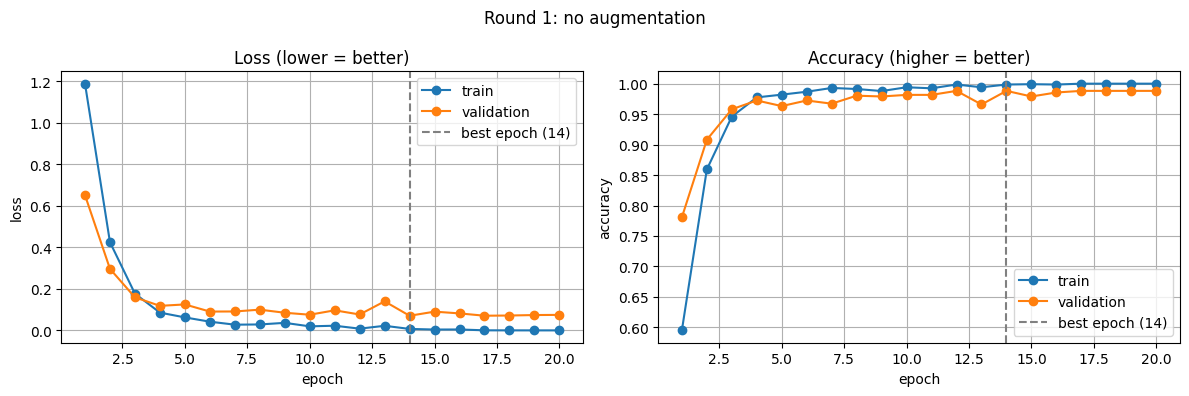

In [16]:
RUNS = {}

def run_experiment(name, channels=(16, 32, 64), kernel_size=3, hidden=128, p_dropout=0.0, augment=False, verbose=False):
    """Train a fresh SimpleCNN with the given settings and store the result."""
    set_seed(SEED)
    tr, va, _ = make_loaders(augment)
    m = SimpleCNN(num_classes, channels, kernel_size, hidden, p_dropout).to(device)
    print(f"\n=== {name} ===  channels={channels} kernel={kernel_size} hidden={hidden} dropout={p_dropout} augment={augment}")
    hist = train_model(m, tr, va, EPOCHS, LR, verbose=verbose)

    m.eval(); preds, labs = [], []
    with torch.no_grad():
        for x, y in va:
            preds.append(m(x.to(device)).argmax(1).cpu()); labs.append(y)
    val_f1 = f1_score(torch.cat(labs).numpy(), torch.cat(preds).numpy(), average="macro")

    b = hist["best_epoch"] - 1
    RUNS[name] = dict(history=hist, state={k: v.cpu().clone() for k, v in m.state_dict().items()},
                      cfg=dict(channels=channels, kernel_size=kernel_size, hidden=hidden, p_dropout=p_dropout, augment=augment),
                      params=count_params(m), train_acc=hist["train_acc"][b], val_acc=hist["val_acc"][b], val_f1=val_f1)
    print(f"best epoch {hist['best_epoch']:2d} | train_acc={hist['train_acc'][b]:.3f} val_acc={hist['val_acc'][b]:.3f} "
          f"val_macro_f1={val_f1:.3f} | params={count_params(m):,} | {hist['seconds']:.0f}s")
    return m, hist

model, history_plain = run_experiment("Round 1: baseline (no augmentation, no dropout)", verbose=True)
plot_history(history_plain, "Round 1: no augmentation", "round1_curves.png")

## 5. Spot the overfitting

Read the two curves like this:

- If the **training accuracy keeps climbing** and the training loss keeps dropping, but the **validation accuracy stalls** and the **validation loss rises again**, the model is **overfitting**: it memorises the training images instead of learning general features.
- The growing gap between the train and validation curves is the overfitting gap.

In Round 1 the training accuracy reached 1.000 by epoch 17 and the training loss fell to 0.000. The validation loss stayed between 0.071 and 0.100 in most epochs from 8 onward, with one spike at epoch 13 (0.140, accuracy 0.966). The validation accuracy settled at 0.988 (best epoch 14). The gap between training and validation accuracy is about 1.2 points, so the model is overfitting only mildly: it memorises the training images, but the validation loss does not climb steadily. In Round 2 (augmentation and dropout) the training accuracy (0.959 to 0.966) stays below the validation accuracy (0.980 to 0.984), because dropout and augmentation are active only during training. Its validation accuracy was still changing at epoch 20, so it may have needed more epochs.

Next we look at what the model learned, then try to reduce the overfitting in Round 2.

## 6. Round 2: augmentation and dropout

We attack the memorisation in two ways.

1. **Data augmentation (transforms).** Every time the model sees a training image we randomly rotate it a little and change its brightness, contrast and colour, so it sees a fresh variation each epoch. It is applied to the **training set only**; validation and test images stay clean. (No horizontal flip here: a mirrored banknote has reversed text.)
2. **Dropout.** During training, half of the neurons of the hidden layer are randomly switched off in every step, so the network cannot depend on any single feature.

Everything else stays the same, so the comparison is fair.

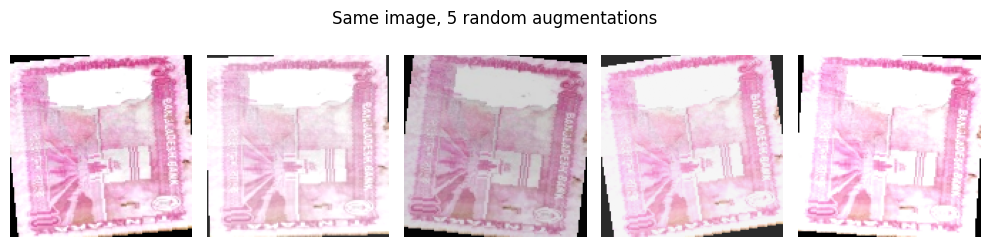

In [17]:
# See the SAME image augmented differently each time
aug_demo = datasets.ImageFolder(RESIZED_DIR, transform=train_transform)
plt.figure(figsize=(10, 2.5))
for i in range(5):
    aug_img, _ = aug_demo[0]         # re-fetching re-applies the random transforms
    plt.subplot(1, 5, i + 1)
    plt.imshow(aug_img.permute(1, 2, 0))
    plt.axis("off")
plt.suptitle("Same image, 5 random augmentations")
plt.tight_layout()
plt.show()


=== Round 2: augmentation + dropout 0.5 ===  channels=(16, 32, 64) kernel=3 hidden=128 dropout=0.5 augment=True
Epoch  1/20  train_loss=1.617 train_acc=0.422  |  val_loss=1.045 val_acc=0.658
Epoch  2/20  train_loss=0.908 train_acc=0.692  |  val_loss=0.540 val_acc=0.834
Epoch  3/20  train_loss=0.639 train_acc=0.783  |  val_loss=0.394 val_acc=0.865
Epoch  4/20  train_loss=0.516 train_acc=0.830  |  val_loss=0.400 val_acc=0.863
Epoch  5/20  train_loss=0.409 train_acc=0.868  |  val_loss=0.247 val_acc=0.917
Epoch  6/20  train_loss=0.336 train_acc=0.894  |  val_loss=0.215 val_acc=0.932
Epoch  7/20  train_loss=0.294 train_acc=0.905  |  val_loss=0.164 val_acc=0.946
Epoch  8/20  train_loss=0.258 train_acc=0.920  |  val_loss=0.129 val_acc=0.958
Epoch  9/20  train_loss=0.223 train_acc=0.927  |  val_loss=0.128 val_acc=0.954
Epoch 10/20  train_loss=0.215 train_acc=0.929  |  val_loss=0.117 val_acc=0.968
Epoch 11/20  train_loss=0.191 train_acc=0.940  |  val_loss=0.116 val_acc=0.959
Epoch 12/20  train

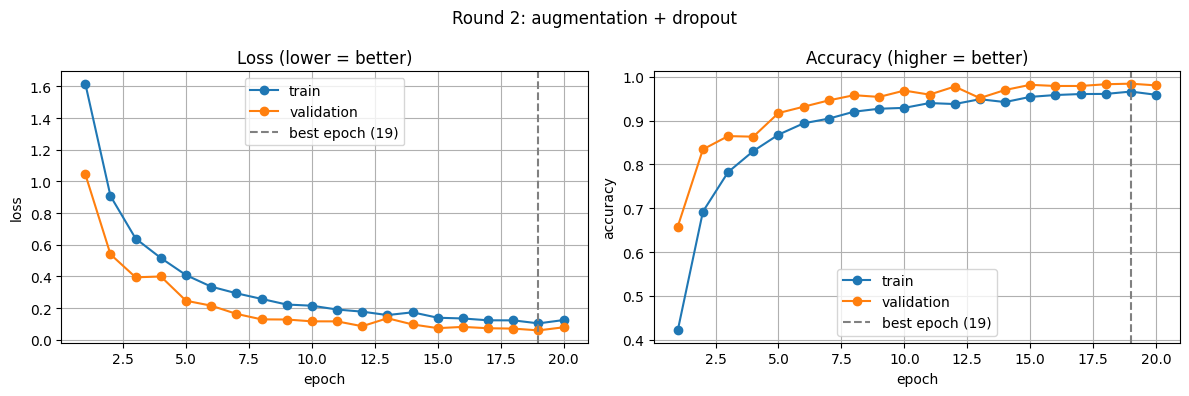

In [ ]:
model_aug, history_aug = run_experiment("Round 2: augmentation + dropout 0.5", p_dropout=0.5, augment=True, verbose=True)
plot_history(history_aug, "Round 2: augmentation + dropout", "round2_curves.png")

### Compare the two rounds

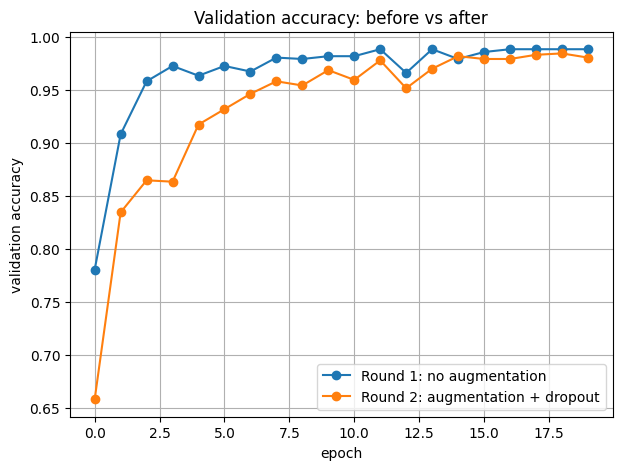

Best val acc (Round 1): 0.988
Best val acc (Round 2): 0.984


In [19]:
plt.figure(figsize=(7, 5))
plt.plot(history_plain["val_acc"], "o-", label="Round 1: no augmentation")
plt.plot(history_aug["val_acc"], "o-", label="Round 2: augmentation + dropout")
plt.title("Validation accuracy: before vs after")
plt.xlabel("epoch"); plt.ylabel("validation accuracy")
plt.legend(); plt.grid(True)
savefig("round1_vs_round2.png"); plt.show()

print(f"Best val acc (Round 1): {max(history_plain['val_acc']):.3f}")
print(f"Best val acc (Round 2): {max(history_aug['val_acc']):.3f}")

## 7. Our own experiments: conv layers, channels, kernel size, hidden layer

Sir's goal is to experiment and learn, not to chase the highest accuracy. Starting from the Round 1 baseline (3 conv layers with 16-32-64 channels, `3 x 3` kernels, hidden layer of 128) we change **one thing at a time**. Same seed, same split, same number of epochs.

| Group | Runs |
|---|---|
| Dropout / augmentation alone | which of the two helps more? |
| Channels | narrow `8-16-32`, wide `32-64-128` |
| Number of conv layers | 2 layers, 4 layers |
| Kernel size | `5 x 5` |
| Hidden layer | 64 and 256 neurons |

> **Parameter-count note.** Every `MaxPool` halves the feature map, so *fewer* conv layers leave a *larger* flattened vector and a much bigger first `Linear` layer. A 2-layer network can have more parameters than the 3-layer one. Read the `params` column with this in mind.

In [20]:
experiments = [
    ("E3 dropout 0.5 only",          dict(p_dropout=0.5)),
    ("E4 augmentation only",         dict(augment=True)),
    ("E5 channels 8-16-32",          dict(channels=(8, 16, 32))),
    ("E6 channels 32-64-128",        dict(channels=(32, 64, 128))),
    ("E7 2 conv layers (16-32)",     dict(channels=(16, 32))),
    ("E8 4 conv layers (16-32-64-128)", dict(channels=(16, 32, 64, 128))),
    ("E9 kernel 5x5",                dict(kernel_size=5)),
    ("E10 hidden layer 64",          dict(hidden=64)),
    ("E11 hidden layer 256",         dict(hidden=256)),
]
for name, kwargs in experiments:
    run_experiment(name, **kwargs)


=== E3 dropout 0.5 only ===  channels=(16, 32, 64) kernel=3 hidden=128 dropout=0.5 augment=False
best epoch  9 | train_acc=0.973 val_acc=0.988 val_macro_f1=0.988 | params=2,122,025 | 55s

=== E4 augmentation only ===  channels=(16, 32, 64) kernel=3 hidden=128 dropout=0.0 augment=True
best epoch 11 | train_acc=0.984 val_acc=0.989 val_macro_f1=0.989 | params=2,122,025 | 82s

=== E5 channels 8-16-32 ===  channels=(8, 16, 32) kernel=3 hidden=128 dropout=0.0 augment=False
best epoch 20 | train_acc=0.998 val_acc=0.980 val_macro_f1=0.979 | params=1,055,897 | 54s

=== E6 channels 32-64-128 ===  channels=(32, 64, 128) kernel=3 hidden=128 dropout=0.0 augment=False
best epoch 20 | train_acc=1.000 val_acc=0.992 val_macro_f1=0.992 | params=4,288,841 | 60s

=== E7 2 conv layers (16-32) ===  channels=(16, 32) kernel=3 hidden=128 dropout=0.0 augment=False
best epoch 12 | train_acc=0.994 val_acc=0.989 val_macro_f1=0.989 | params=4,200,681 | 54s

=== E8 4 conv layers (16-32-64-128) ===  channels=(16, 3

,experiment,params,best_epoch,train_acc,val_acc,gap,val_macro_f1,seconds
0,E6 channels 32-64-128,4288841,20,1.000,0.992,0.008,0.992,60
1,E7 2 conv layers (16-32),4200681,12,0.994,0.989,0.005,0.989,54
2,E4 augmentation only,2122025,11,0.984,0.989,-0.006,0.989,82
3,E9 kernel 5x5,2163753,18,0.994,0.989,0.005,0.989,55
4,E10 hidden layer 64,1072809,10,0.995,0.988,0.007,0.989,55
5,"Round 1: baseline (no augmentation, no dropout)",2122025,14,0.999,0.988,0.010,0.988,60
6,E3 dropout 0.5 only,2122025,9,0.973,0.988,-0.015,0.988,55
7,E11 hidden layer 256,4220457,14,1.000,0.987,0.013,0.986,55
8,Round 2: augmentation + dropout 0.5,2122025,19,0.966,0.984,-0.018,0.984,82
9,E5 channels 8-16-32,1055897,20,0.998,0.980,0.017,0.979,54


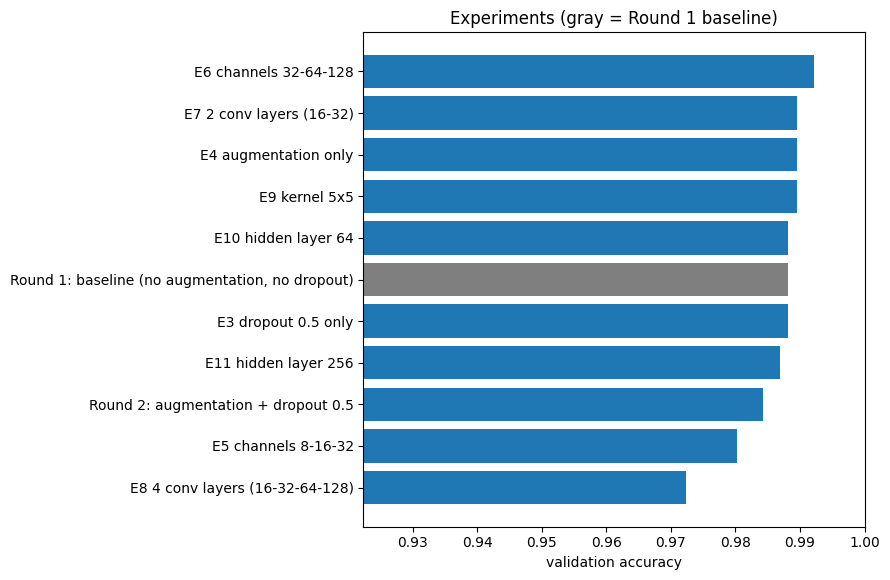

Validation split = 761 images. One standard error of an accuracy near 0.99 is about 0.4 percentage points,
so differences smaller than roughly 0.8 points are within noise unless repeated with several seeds.


In [21]:
rows = [dict(experiment=n, params=r["params"], best_epoch=r["history"]["best_epoch"], train_acc=r["train_acc"],
             val_acc=r["val_acc"], gap=r["train_acc"] - r["val_acc"], val_macro_f1=r["val_f1"],
             seconds=round(r["history"]["seconds"])) for n, r in RUNS.items()]
results_df = (pd.DataFrame(rows).sort_values(["val_acc", "val_macro_f1"], ascending=False, kind="stable")
              .reset_index(drop=True))
display(results_df.round(3))

order = results_df.iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 0.4 * len(order) + 1.5))
ax.barh(order["experiment"], order["val_acc"],
        color=["tab:gray" if n.startswith("Round 1") else "tab:blue" for n in order["experiment"]])
ax.set_xlabel("validation accuracy"); ax.set_title("Experiments (gray = Round 1 baseline)")
ax.set_xlim(max(0, order["val_acc"].min() - 0.05), min(1.0, order["val_acc"].max() + 0.02))
plt.tight_layout(); savefig("experiments_val_acc.png"); plt.show()

n_val = len(idx_val)
p0 = RUNS["Round 1: baseline (no augmentation, no dropout)"]["val_acc"]
se0 = math.sqrt(p0 * (1 - p0) / n_val)
print(f"Validation split = {n_val} images. One standard error of an accuracy near {p0:.2f} is about {100 * se0:.1f} percentage points,")
print(f"so differences smaller than roughly {200 * se0:.1f} points are within noise unless repeated with several seeds.")

### What the experiments show (write after running)
* Dropout vs augmentation: The baseline had a train-minus-validation accuracy gap of +1.1 points. Dropout alone (E3) gave -1.5 and augmentation alone (E4) gave -0.5, so both shrank the gap. Validation accuracy did not improve (E3 0.988, E4 0.989, baseline 0.988). Round 2, with both together, scored 0.984. With so little overfitting to remove, regularisation gave no measurable gain here.
* Channels: Narrow channels 8-16-32 (E5) gave 0.980 with 1.06M parameters. The baseline 16-32-64 gave 0.988 with 2.12M. Wide channels 32-64-128 (E6) gave 0.992 with 4.29M. Training time stayed about 54 to 60 s per run.
* Number of conv layers: Two layers (E7) gave 0.989, three (baseline) 0.988, four (E8) 0.972. E7 has more parameters (4.20M) than the three-layer model (2.12M), because fewer pooling steps leave a larger flattened vector. E8 (1.15M parameters) was still improving at epoch 20, which may explain its lower score (my guess, not tested).
* Kernel size and hidden layer: A 5x5 kernel (E9) gave 0.989, hidden size 64 (E10) 0.988 and hidden size 256 (E11) 0.987. Halving the hidden layer to 64 cut the parameters to 1.07M with no loss in accuracy.
* Differences that may be noise: One standard error on the validation set is about 0.4 points, so differences under about 0.8 points are within noise. Only E8 (-1.6 points) and E14 in section 11 (-3.7 points) are clearly lower than the baseline. E6 scored highest (0.992) but only 0.4 points above the baseline, so I cannot say it is really better. Each configuration was run once, with one seed.

## 8. Final model and test evaluation

We take the experiment with the highest validation accuracy (set `FINAL_NAME` yourself to choose another) and evaluate it **once** on the test images, which no experiment used.

In [22]:
FINAL_NAME = results_df.iloc[0]["experiment"]       # or e.g. "Round 2: augmentation + dropout 0.5"
cfg = RUNS[FINAL_NAME]["cfg"]
print("Final model:", FINAL_NAME, cfg)

final_model = SimpleCNN(num_classes, cfg["channels"], cfg["kernel_size"], cfg["hidden"], cfg["p_dropout"]).to(device)
final_model.load_state_dict(RUNS[FINAL_NAME]["state"])
final_history = RUNS[FINAL_NAME]["history"]
_, _, test_loader = make_loaders(cfg["augment"])

def get_predictions(model, loader):
    model.eval()
    preds, targets_, probs = [], [], []
    with torch.no_grad():
        for imgs, labels in loader:
            out = F.softmax(model(imgs.to(device)), dim=1).cpu()
            probs.append(out); preds.append(out.argmax(1)); targets_.append(labels)
    return torch.cat(preds).numpy(), torch.cat(targets_).numpy(), torch.cat(probs).numpy()

y_pred, y_true, probs = get_predictions(final_model, test_loader)
test_acc = accuracy_score(y_true, y_pred)
test_f1 = f1_score(y_true, y_pred, average="macro")
half_ci = 1.96 * math.sqrt(test_acc * (1 - test_acc) / len(y_true))
print(f"\nTEST accuracy : {test_acc:.4f}  (approx. 95% interval +/- {half_ci:.3f}, n = {len(y_true)})")
print(f"TEST macro-F1 : {test_f1:.4f}")
print(f"Validation accuracy of the same model: {RUNS[FINAL_NAME]['val_acc']:.4f}")

Final model: E6 channels 32-64-128 {'channels': (32, 64, 128), 'kernel_size': 3, 'hidden': 128, 'p_dropout': 0.0, 'augment': False}

TEST accuracy : 0.9869  (approx. 95% interval +/- 0.008, n = 761)
TEST macro-F1 : 0.9871
Validation accuracy of the same model: 0.9921


## 9. Result analysis

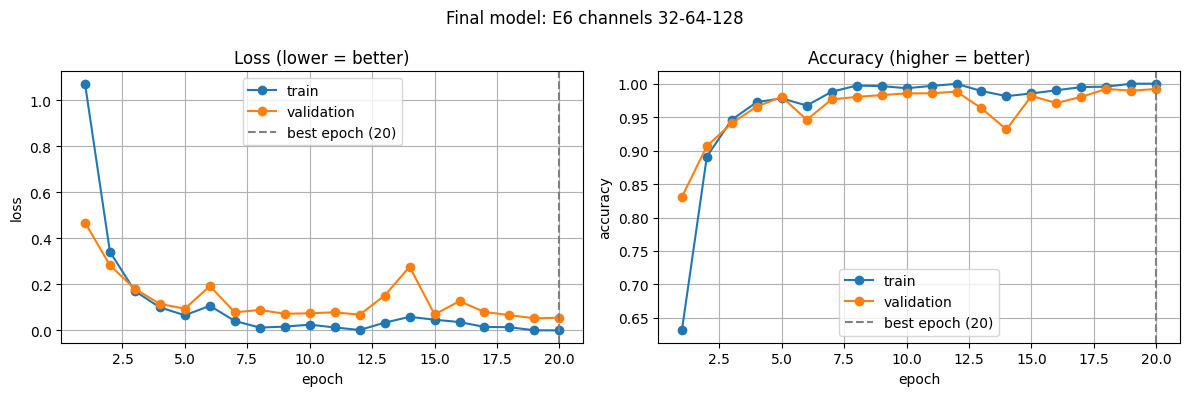

In [23]:
plot_history(final_history, f"Final model: {FINAL_NAME}", "final_curves.png")

### Visualize the filters and feature maps

1. **The filters** of the first convolution layer: because the input has 3 channels (RGB), each filter is a tiny colour patch. They tend to become edge and colour detectors.
2. **Feature maps:** the response of the filters to a real image. Bright spots show where a pattern was found. Early layers see simple patterns (edges, colours); the last layer sees small, abstract maps.

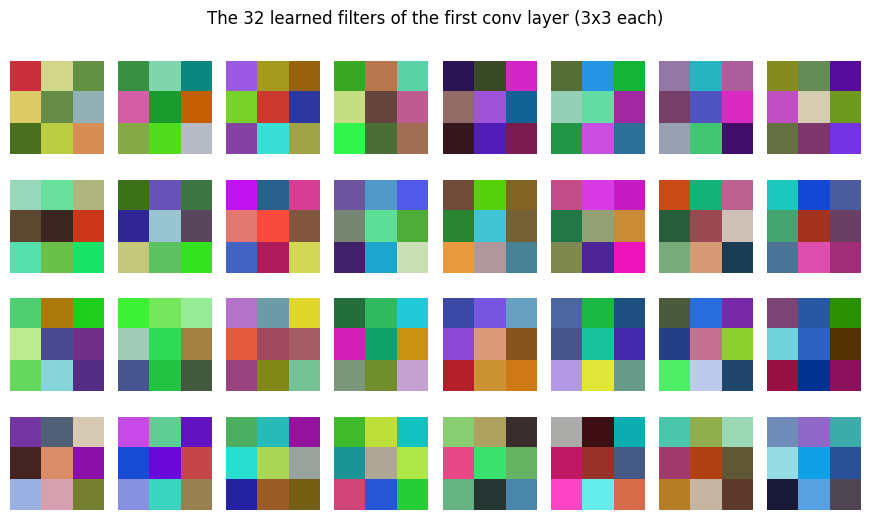

In [24]:
# (1) Filters of the first conv layer
first_conv = final_model.conv_layers[0]
weights = first_conv.weight.data.clone().cpu()                      # [filters, 3, k, k]
weights = (weights - weights.min()) / (weights.max() - weights.min() + 1e-8)   # scale to [0, 1] for display

n = weights.shape[0]; cols = 8; rows_ = math.ceil(n / cols)
plt.figure(figsize=(cols * 1.1, rows_ * 1.2 + 0.6))
for i in range(n):
    plt.subplot(rows_, cols, i + 1)
    plt.imshow(weights[i].permute(1, 2, 0), interpolation="nearest")
    plt.axis("off")
plt.suptitle(f"The {n} learned filters of the first conv layer ({weights.shape[2]}x{weights.shape[3]} each)")
plt.tight_layout(); savefig("first_layer_filters.png"); plt.show()

Input class: 20
First conv output shape: (32, 128, 128) | Last conv output shape: (128, 32, 32)


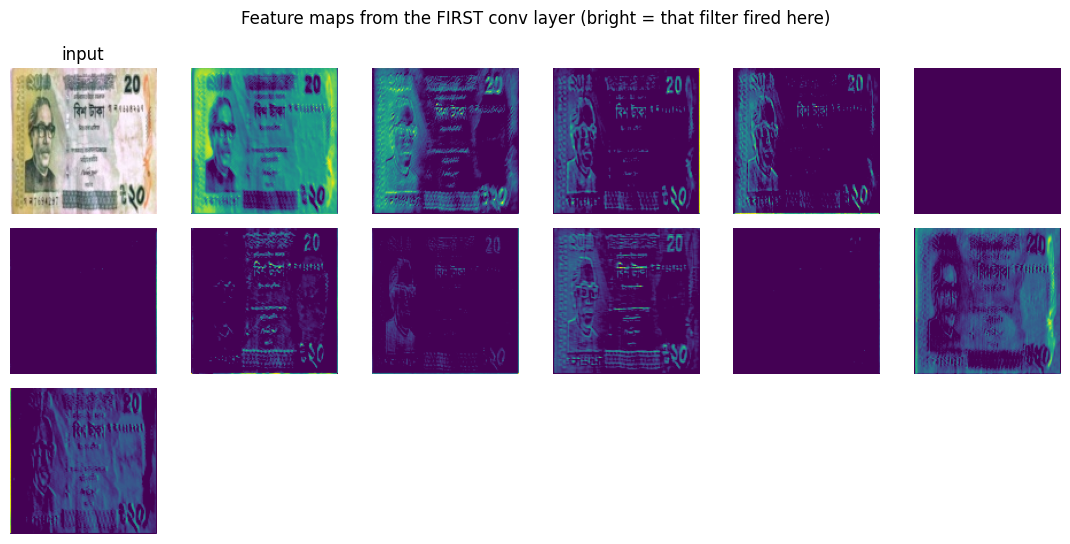

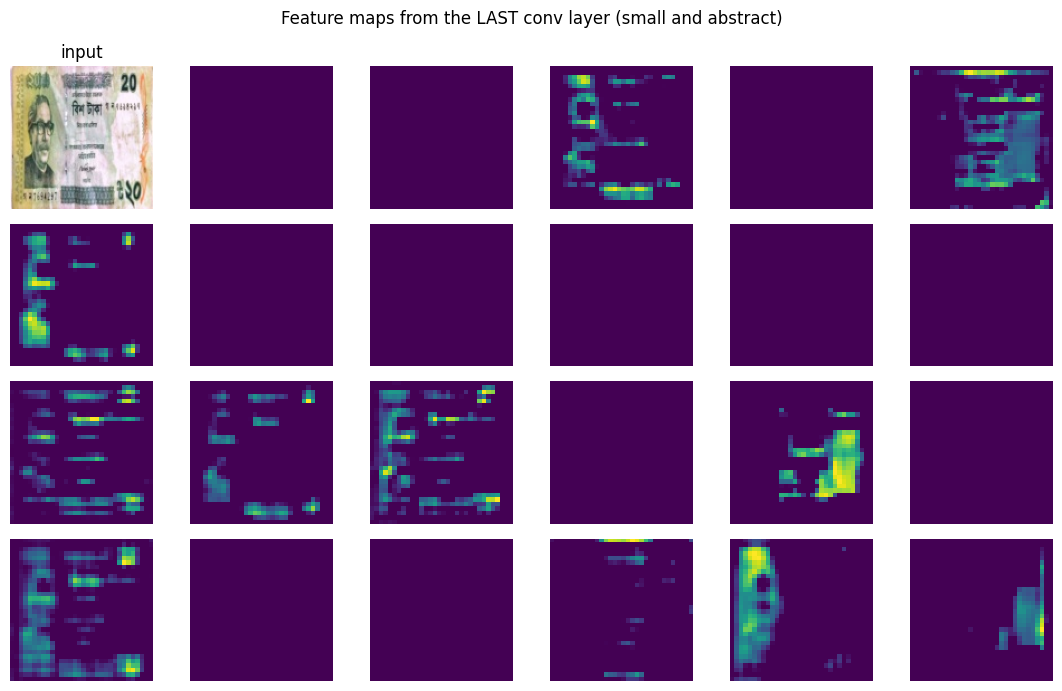

In [25]:
# (2) Feature maps of the first and the last conv layer for one correctly classified test image
test_full = datasets.ImageFolder(RESIZED_DIR, transform=basic_transform)
correct_idx = np.where(y_true == y_pred)[0]
k = int(correct_idx[0]) if len(correct_idx) else 0
img, label = Subset(test_full, idx_test)[k]
x = img.unsqueeze(0).to(device)

conv_positions = [i for i, m in enumerate(final_model.conv_layers) if isinstance(m, nn.Conv2d)]
final_model.eval()
with torch.no_grad():
    early = F.relu(final_model.conv_layers[:conv_positions[0] + 1](x)).cpu()[0]     # first conv layer
    last = F.relu(final_model.conv_layers[:conv_positions[-1] + 1](x)).cpu()[0]     # last conv layer
print("Input class:", class_names[label])
print("First conv output shape:", tuple(early.shape), "| Last conv output shape:", tuple(last.shape))

plt.figure(figsize=(11, 5.5))
plt.subplot(3, 6, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(min(12, early.shape[0])):
    plt.subplot(3, 6, i + 2); plt.imshow(early[i], cmap="viridis"); plt.axis("off")
plt.suptitle("Feature maps from the FIRST conv layer (bright = that filter fired here)")
plt.tight_layout(); savefig("feature_maps_first.png"); plt.show()

plt.figure(figsize=(11, 7))
plt.subplot(4, 6, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(min(23, last.shape[0])):
    plt.subplot(4, 6, i + 2); plt.imshow(last[i], cmap="viridis"); plt.axis("off")
plt.suptitle("Feature maps from the LAST conv layer (small and abstract)")
plt.tight_layout(); savefig("feature_maps_last.png"); plt.show()

### Confusion matrix and classification report (test set)

The confusion matrix shows, for each true class (rows), which class the model predicted (columns). The diagonal holds the correct predictions. The report gives precision, recall and F1 per class; **macro-F1** averages them so that small classes count as much as large ones.

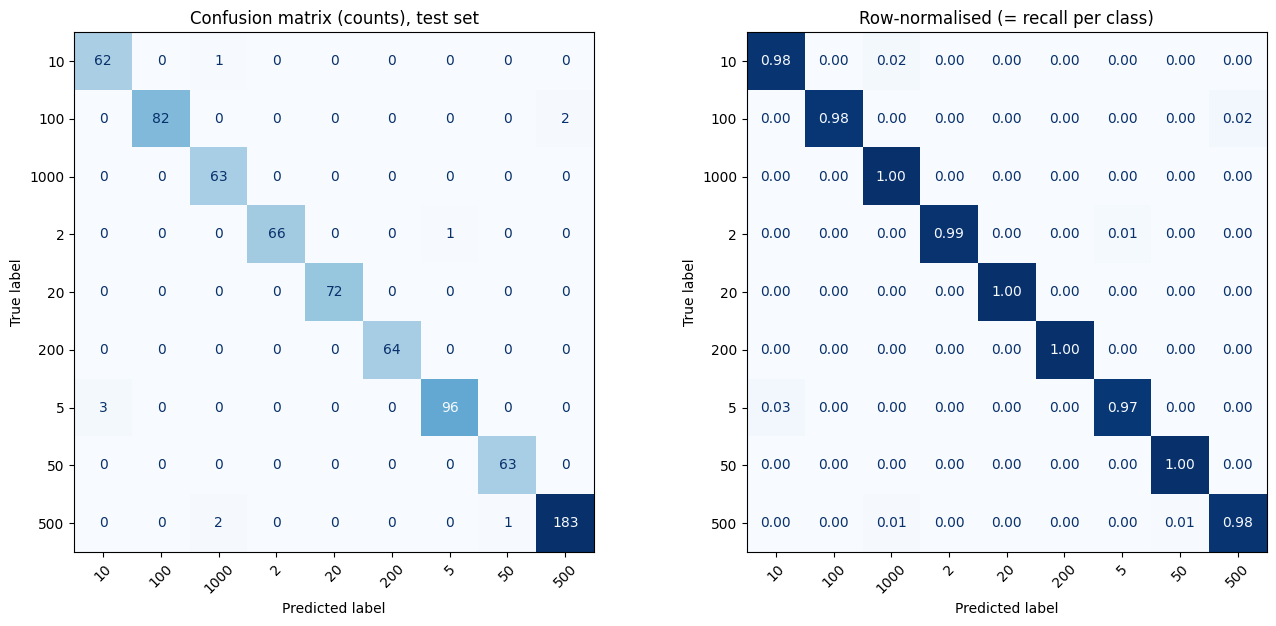

              precision    recall  f1-score   support

          10      0.954     0.984     0.969        63
         100      1.000     0.976     0.988        84
        1000      0.955     1.000     0.977        63
           2      1.000     0.985     0.992        67
          20      1.000     1.000     1.000        72
         200      1.000     1.000     1.000        64
           5      0.990     0.970     0.980        99
          50      0.984     1.000     0.992        63
         500      0.989     0.984     0.987       186

    accuracy                          0.987       761
   macro avg      0.986     0.989     0.987       761
weighted avg      0.987     0.987     0.987       761

Most frequent confusions (true -> predicted):
    3 x  5  ->  10
    2 x  500  ->  1000
    2 x  100  ->  500
    1 x  500  ->  50
    1 x  2  ->  5
    1 x  10  ->  1000


In [26]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
side = max(5, 0.7 * num_classes)
fig, axes = plt.subplots(1, 2, figsize=(2 * side + 1, side))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False, xticks_rotation=45)
ConfusionMatrixDisplay(cm_norm, display_labels=class_names).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False, xticks_rotation=45)
axes[0].set_title("Confusion matrix (counts), test set"); axes[1].set_title("Row-normalised (= recall per class)")
plt.tight_layout(); savefig("confusion_matrix.png"); plt.show()

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

off = sorted(((cm[i, j], class_names[i], class_names[j]) for i in range(num_classes) for j in range(num_classes)
              if i != j and cm[i, j] > 0), reverse=True)
print("Most frequent confusions (true -> predicted):")
for n_, t, p in off[:8]:
    print(f"  {n_:3d} x  {t}  ->  {p}")

### Misclassified images and random predictions

Total misclassified samples: 10 of 761


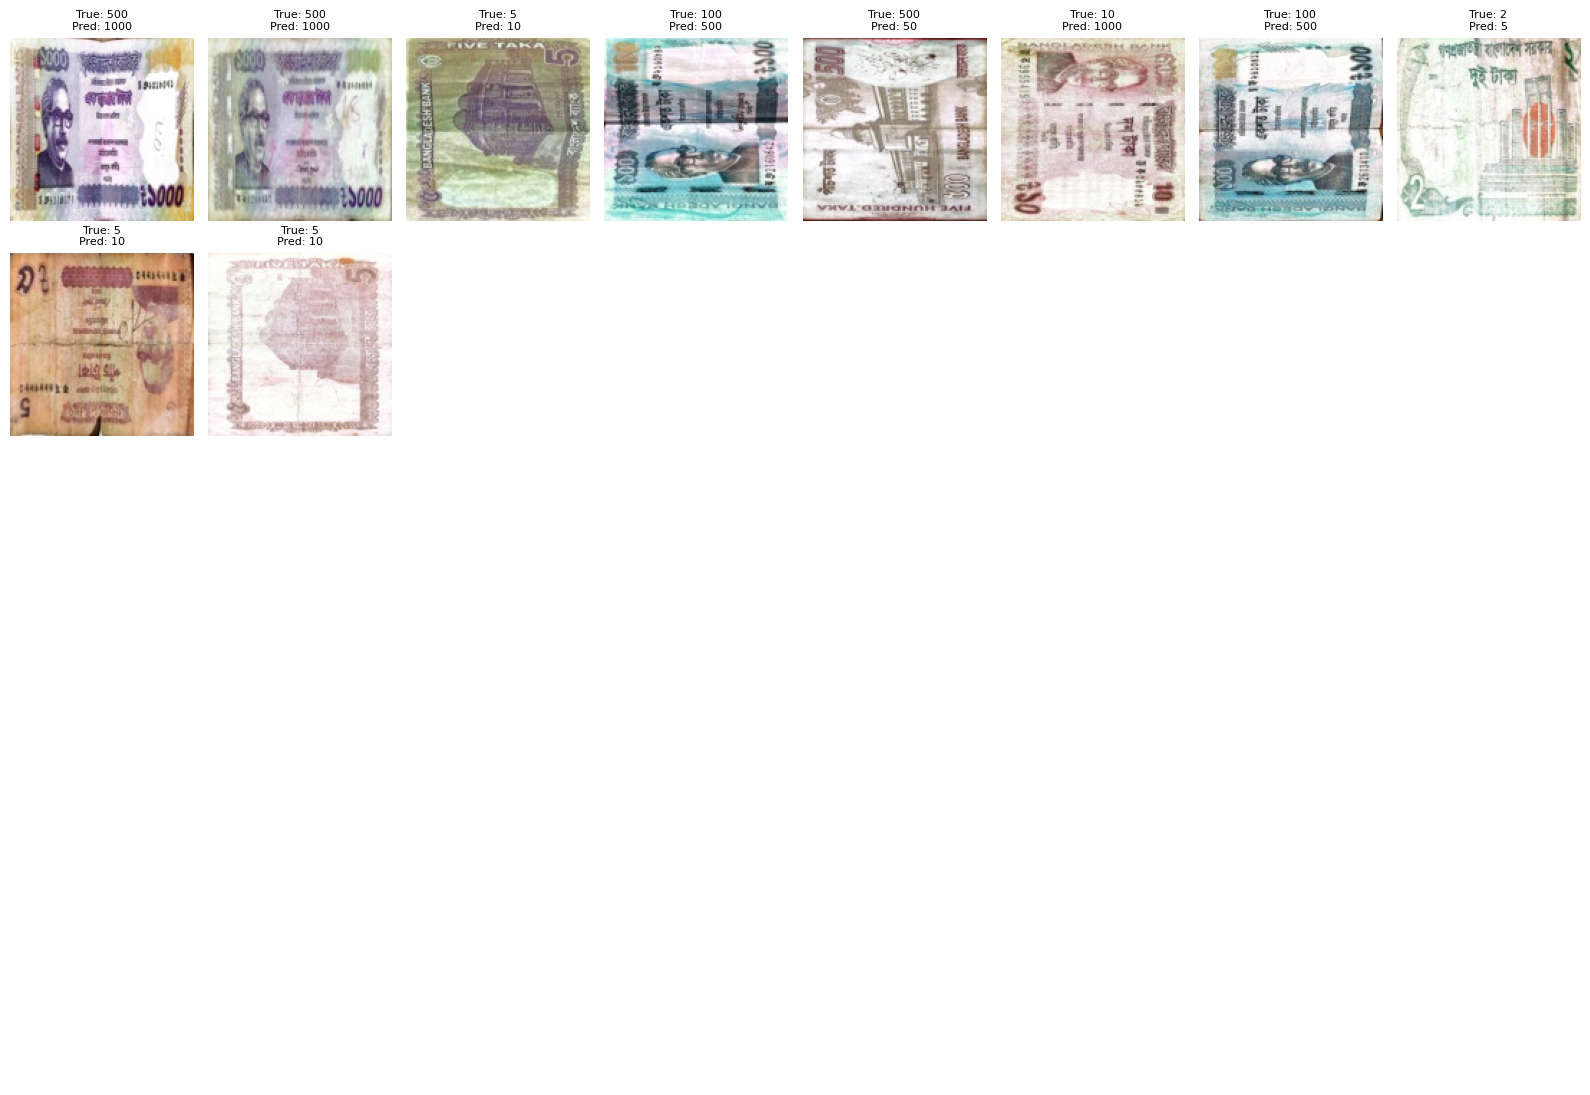

In [27]:
# Misclassified test images, most confident mistakes first
mis = np.where(y_true != y_pred)[0]
mis = mis[np.argsort(-probs[mis].max(axis=1))]
print(f"Total misclassified samples: {len(mis)} of {len(y_true)}")

if len(mis):
    num_rows, num_cols = 5, 8
    num_to_show = min(num_rows * num_cols, len(mis))
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols * 2, num_rows * 2.2))
    axes = axes.flatten()
    test_subset = Subset(test_full, idx_test)
    for ax in axes:
        ax.axis("off")
    for ax, k in zip(axes, mis[:num_to_show]):
        im_, _ = test_subset[k]
        ax.imshow(im_.permute(1, 2, 0).numpy())
        ax.set_title(f"True: {class_names[y_true[k]]}\nPred: {class_names[y_pred[k]]}", fontsize=8)
    plt.tight_layout(); savefig("misclassified.png"); plt.show()

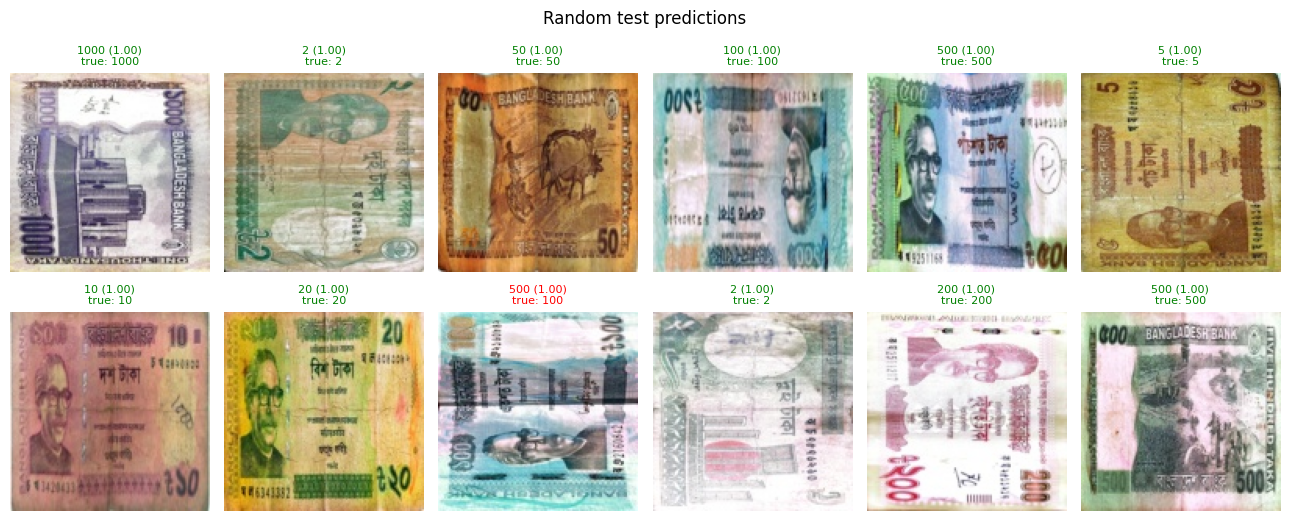

In [28]:
# Predictions on 12 random test images (green = correct, red = wrong) with the model's confidence
pick = np.random.default_rng(SEED).choice(len(y_true), size=min(12, len(y_true)), replace=False)
test_subset = Subset(test_full, idx_test)
plt.figure(figsize=(13, 5.5))
for i, k in enumerate(pick):
    im_, _ = test_subset[k]
    plt.subplot(2, 6, i + 1)
    plt.imshow(im_.permute(1, 2, 0).numpy()); plt.axis("off")
    plt.title(f"{class_names[y_pred[k]]} ({probs[k].max():.2f})\ntrue: {class_names[y_true[k]]}", fontsize=8,
              color="green" if y_pred[k] == y_true[k] else "red")
plt.suptitle("Random test predictions"); plt.tight_layout(); savefig("random_predictions.png"); plt.show()

In [29]:
# Save everything needed for the report
results_df.round(4).to_csv(os.path.join(OUT_DIR, "experiment_results.csv"), index=False)
pd.DataFrame({k: v for k, v in final_history.items() if isinstance(v, list)}).to_csv(os.path.join(OUT_DIR, "final_history.csv"), index=False)
torch.save({"state_dict": RUNS[FINAL_NAME]["state"], "cfg": cfg, "class_names": class_names}, os.path.join(OUT_DIR, "final_cnn.pt"))
with open(os.path.join(OUT_DIR, "final_summary.json"), "w") as f:
    json.dump({"source_dirs": SRC_DIRS, "n_images": int(len(targets)), "n_classes": num_classes, "final_experiment": FINAL_NAME,
               "test_accuracy": float(test_acc), "test_macro_f1": float(test_f1),
               "val_accuracy": float(RUNS[FINAL_NAME]["val_acc"]), "seed": SEED}, f, indent=2)
print("Saved to", OUT_DIR)

Saved to /kaggle/working


## 10. Recap and discussion

| Concept | What it is |
|---|---|
| **Filter / kernel** | a small grid that detects one pattern (edge, colour, texture) |
| **Convolution layer** | a stack of filters producing feature maps |
| **Pooling** | shrinks feature maps, keeps the strongest signals |
| **Hidden layer** | a fully connected layer between the flattened features and the output |
| **Overfitting** | high training accuracy but lower validation accuracy (memorising) |
| **Augmentation, dropout** | ways to reduce overfitting |
| **Train / validation / test** | learn on one, compare experiments on the second, report the final result on the third |

**Dataset.** I chose BanglaTaka because it meets the assignment limits (5,073 images against the minimum of 2,000, and 1.71 GB against the maximum of 2.5 GB), it was published through Mendeley Data and Data in Brief, and it uses local currency. It has 9 classes (2, 5, 10, 20, 50, 100, 200, 500, 1000 Taka). The classes are imbalanced: 500 Taka has 1,243 images (24.5%) and 50 Taka has 416 (8.2%), a ratio of 3.0. The original photos vary in size (200 sampled: about 520 to 3,106 px wide and 476 to 3,384 px tall), so they were resized to 128 x 128.

**Model.** The final model (E6) has three blocks of Conv (3x3, padding 1) - ReLU - MaxPool(2x2) with 32, 64 and 128 filters, then a flatten (128 x 16 x 16 = 32,768 values), a hidden layer of 128 neurons with ReLU, and an output layer of 9 scores. It has 4,288,841 trainable parameters, no dropout and no augmentation. I chose it because it had the highest validation accuracy of all experiments (0.992), as decided by a fixed rule. Its advantage over the baseline is within noise.

**Results.** On the 761 test images the final model reached 98.69% accuracy (about +/- 0.8 points) and a macro-F1 of 0.987. The validation accuracy of the same model was 99.21%, so the test result is close to it. Classes 20 and 200 were classified perfectly (F1 1.000). The weakest per-class scores were class 10 (precision 0.954) and class 1000 (precision 0.955). The lowest recall was class 5 (0.970).

**Errors.** The confusion matrix is almost entirely diagonal. The ten errors are 5 -> 10 (3 images), 100 -> 500 (2), 500 -> 1000 (2), and 10 -> 1000, 2 -> 5 and 500 -> 50 (1 each). In the misclassified images, several notes are worn, faded or shown from the back (for example the back of a 5 Taka note and of a 2 Taka note), and some are photographed sideways, but sideways notes are also classified correctly elsewhere, so rotation alone does not explain the errors. The two most confident mistakes (true 500, predicted 1000) appear to show a 1000 Taka note, so they may be labelling errors in the dataset. The model was also very confident when wrong: even the wrong example in the random-prediction figure had a confidence of 1.00. With only ten errors, these patterns are weak and untested.

**Filters and feature maps.** The first conv layer has 32 filters of size 3x3x3 (RGB). For the example image, its feature maps are 128 x 128, the same size as the input, and the last conv layer's maps are 32 x 32 with 128 channels. The 32 first-layer filters look like small colourful patches without clear edge structure, which is hard to read at 3x3 pixels. In the feature maps of the example 20 Taka note, many first-layer maps outline the portrait, the text and the digits, one map responds to the whole note, and a few maps stay dark. The last-layer maps are coarse (32 x 32); about half of the ones shown are inactive, and the active ones highlight regions such as the portrait, text lines and the denomination number rather than anything that looks like the original image.
**Limitations.**

- Each configuration was trained once with one seed, so small differences are within noise.
- Photos of the same note taken in bursts may appear in both train and test, which can inflate accuracy; the dataset has no group labels, so a random split cannot rule this out.
- Banknote images are stretched to a square, which distorts the note slightly.
- A CNN trained from scratch on a small dataset; a pretrained network would probably score higher (not tested here).

## 11. Extra experiments: padding, pooling and stride

These three runs were done after the final model was chosen, so they are not in the results table of section 7 and do not affect the final model. Same seed, split and number of epochs as the other runs; one factor changed at a time.

| Run | Change | Val acc |
|---|---|---|
| Baseline | padding 1 ("same"), max pooling, stride 1 | 0.988 |
| E12 | no padding | 0.987 |
| E13 | average pooling instead of max pooling | 0.986 |
| E14 | stride 2 in every conv layer | 0.951 |

E12 (no padding, 0.987) and E13 (average pooling, 0.986) are within noise of the baseline (0.988). Without padding, each 3x3 conv loses 2 pixels, so the maps shrink to 14 x 14 before flattening instead of 16 x 16, which cuts the parameters from 2.12M to 1.63M. E14 (stride 2) is clearly lower (0.951) and has only 57,641 parameters. Its training accuracy was 0.972 and it was still improving at epoch 20, so it underfits rather than overfits. A likely reason, which I did not test, is that the stride skips positions and leaves only a 2 x 2 map before the classifier, so fine details are lost. The E14 printout above shows 0.991 for the baseline from an earlier run; the baseline in this notebook is 0.988.)

In [30]:
class CNNVariant(nn.Module):
    """Same CNN as SimpleCNN, but padding and pooling type can be changed."""
    def __init__(self, num_classes, channels=(16, 32, 64), kernel_size=3, hidden=128, padding=1, pool="max"):
        super().__init__()
        layers, in_ch = [], 3
        for out_ch in channels:
            layers += [nn.Conv2d(in_ch, out_ch, kernel_size, padding=padding),
                       nn.ReLU(),
                       nn.MaxPool2d(2) if pool == "max" else nn.AvgPool2d(2)]
            in_ch = out_ch
        self.conv_layers = nn.Sequential(*layers)
        with torch.no_grad():                      # find the flatten size automatically
            flat = self.conv_layers(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).numel()
        self.fc_layers = nn.Sequential(nn.Flatten(), nn.Linear(flat, hidden), nn.ReLU(), nn.Linear(hidden, num_classes))
    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))

base_val = RUNS["Round 1: baseline (no augmentation, no dropout)"]["val_acc"]
print(f"Baseline (padding=1 'same', max pooling): val_acc = {base_val:.3f}\n")

for name, kw in [("E12 no padding (padding=0)", dict(padding=0)),
                 ("E13 average pooling instead of max", dict(pool="avg"))]:
    set_seed(SEED)
    tr, va, _ = make_loaders(False)
    m = CNNVariant(num_classes, **kw).to(device)
    hist = train_model(m, tr, va, EPOCHS, LR, verbose=False)
    b = hist["best_epoch"] - 1
    print(f"{name}: best epoch {hist['best_epoch']}, train_acc={hist['train_acc'][b]:.3f}, "
          f"val_acc={hist['val_acc'][b]:.3f}, params={count_params(m):,}")

Baseline (padding=1 'same', max pooling): val_acc = 0.988

E12 no padding (padding=0): best epoch 20, train_acc=1.000, val_acc=0.987, params=1,630,505
E13 average pooling instead of max: best epoch 20, train_acc=0.996, val_acc=0.986, params=2,122,025


In [31]:
class CNNStride(nn.Module):
    """Same CNN, but the conv layers use a chosen stride."""
    def __init__(self, num_classes, channels=(16, 32, 64), kernel_size=3, hidden=128, stride=1):
        super().__init__()
        layers, in_ch = [], 3
        for out_ch in channels:
            layers += [nn.Conv2d(in_ch, out_ch, kernel_size, stride=stride, padding=kernel_size // 2),
                       nn.ReLU(), nn.MaxPool2d(2)]
            in_ch = out_ch
        self.conv_layers = nn.Sequential(*layers)
        with torch.no_grad():
            flat = self.conv_layers(torch.zeros(1, 3, IMG_SIZE, IMG_SIZE)).numel()
        self.fc_layers = nn.Sequential(nn.Flatten(), nn.Linear(flat, hidden), nn.ReLU(), nn.Linear(hidden, num_classes))
    def forward(self, x):
        return self.fc_layers(self.conv_layers(x))

set_seed(SEED)
tr, va, _ = make_loaders(False)
m = CNNStride(num_classes, stride=2).to(device)
hist = train_model(m, tr, va, EPOCHS, LR, verbose=False)
b = hist["best_epoch"] - 1
print(f"E14 stride 2: best epoch {hist['best_epoch']}, train_acc={hist['train_acc'][b]:.3f}, "
      f"val_acc={hist['val_acc'][b]:.3f}, params={count_params(m):,} (baseline val_acc {base_val:.3f}, params 2,122,025)")

E14 stride 2: best epoch 20, train_acc=0.972, val_acc=0.951, params=57,641 (baseline val_acc 0.991, params 2,122,025)
